In [1]:
"""
here is a notebook for making figures haha finally
"""

'\nhere is a notebook for making figures haha finally\n'

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imageio as iio
from astropy.io import fits

In [2]:
from tqdm.auto import tqdm
import os
from pylab import cm
import matplotlib as mpl
import get_postage_stamps as gpsf
import pandas as pd

In [3]:
import plot_time_series as pts
import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)

In [4]:
import review_findings_functions as ff

In [5]:
# some matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [6]:
fnam = "ztf_20210622237812_000677_zr_c03_o.fits.fz"

In [7]:
fnam[:40]

'ztf_20210622237812_000677_zr_c03_o.fits.'

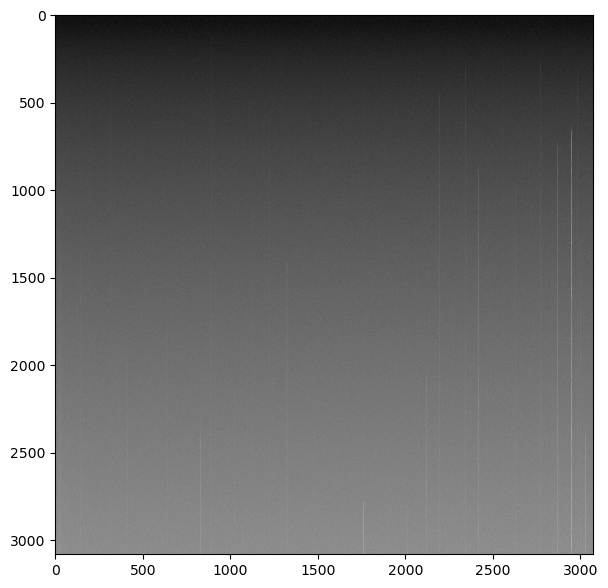

In [5]:
hdul = fits.open(
    "/lustre/lrspec/ZTF_data/20210622/ztf_20210622237812_000677_zr_c03_o.fits.fz"
)
file1_array = hdul[1].data
norm = (file1_array - np.min(file1_array)) / (np.max(file1_array) - np.min(file1_array))

plt.imshow(np.sqrt(norm))

In [7]:
# some stuff that will stay the same
wid = 10
fpath_image = "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/images/"
fpath_info = "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/info/"
fpath_extractions = "/lustre/lrspec/ZTF_data/2022_1014_copy/full_transient_extractions/"

image_directory = os.fsencode(fpath_image)

In [8]:
testimp = np.load(
    "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/images/ztf_20221014279051_000501_zr_c16_x_0025._implanted10.npy"
)
testpreds = np.load(
    "/lustre/lrspec/ZTF_data/2022_1014_copy/full_transient_extractions/ztf_20221014279051_000501_zr_c16_x_0025._extraction_predsarray.npy"
)

In [9]:
def show_preds_pretty_streak(image, pimg, file_info, df_this_one):
    """
    plotting function for CNN output
    """

    pimg = pimg.reshape(3052, 3060, 3)
    image = image[10:-10, 10:-10]
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_title("Image with implantations", fontsize=25)  # , fontweight='bold')
    # plt.colorbar()
    ax[1].imshow(
        pimg[:, :, 2],
    )  # cmap='viridis')
    ax[1].set_title("Streak prediction", fontsize=25)
    ax[2].imshow(pimg[:, :, 1] > 0.99)  # , cmap='viridis')
    ax[2].set_title("Transient prediction", fontsize=25)
    ax[0].set_axis_off()
    ax[1].set_axis_off()
    ax[2].set_xticks([])
    ax[2].set_yticks([])
    ax[2].set_xticklabels([])
    ax[2].set_yticklabels([])
    for trans in file_info:
        xcoord = trans[1]
        ycoord = trans[0]
        cir = plt.Circle((xcoord, ycoord), 80, color="r", fill=False)
        # ax[2].add_patch(cir)
        # cir2 = plt.Circle((xcoord, ycoord), 80, color='r',fill=False)

        ax[0].add_patch(cir)
    for i in range(len(df_this_one)):
        xcoord = df_this_one.iloc[i]["row_from_nn"]
        ycoord = df_this_one.iloc[i]["col_from_nn"]
        if df_this_one.iloc[i]["correctness"] == True:
            cir2 = plt.Circle((xcoord, ycoord), 80, color="r", fill=False)
            cir3 = plt.Circle((xcoord + 10, ycoord + 10), 80, color="r", fill=False)
            ax[0].add_patch(cir3)
        else:
            cir2 = plt.Circle((xcoord, ycoord), 80, color="r", fill=False)
        ax[2].add_patch(cir2)

    plt.tight_layout()
    plt.show()

In [11]:
df_this_one = df_checked_detections[
    df_checked_detections["filename"] == "ztf_20221014279051_000501_zr_c16_x_0025."
]

NameError: name 'df_checked_detections' is not defined

In [10]:
show_preds_pretty_streak(
    testimp,
    testpreds,
    get_file_info("ztf_20221014279051_000501_zr_c16_x_0025."),
    df_this_one,
)

NameError: name 'get_file_info' is not defined

In [185]:
def show_preds_tf(
    filename, df_checked_detections, path="/lustre/lrspec/ZTF_data/2022_1014_copy/"
):
    # image, pimg, file_info, df_this_one):

    """
    plotting function for CNN output
    """
    image = np.load(path + "implantations/images/" + filename + "_implanted10.npy")
    pimg = np.load(
        path + "full_transient_extractions/" + filename + "_extraction_predsarray.npy"
    )
    pimg = pimg.reshape(3052, 3060, 3)
    image = image[10:-10, 10:-10]
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_title("Image with implantations", fontsize=25)  # , fontweight='bold')
    # plt.colorbar()
    # ax[1].imshow(pimg[:,:,2],)# cmap='viridis')
    # ax[1].set_title("Streak prediction", fontsize=25)
    ax[1].imshow(pimg[:, :, 1] > 0.99)  # , cmap='viridis')
    ax[1].set_title("Transient prediction", fontsize=25)
    ax[0].set_axis_off()
    # ax[1].set_axis_off()
    ax[1].set_xticks([])
    ax[1].set_yticks([])
    ax[1].set_xticklabels([])
    ax[1].set_yticklabels([])
    for trans in get_file_info(filename):
        xcoord = trans[1]
        ycoord = trans[0]
        cir = plt.Circle((xcoord, ycoord), 80, color="deepskyblue", fill=False)
        # ax[2].add_patch(cir)
        # cir2 = plt.Circle((xcoord, ycoord), 80, color='r',fill=False)

        ax[0].add_patch(cir)
    df_this_one = df_checked_detections[df_checked_detections["filename"] == filename]
    for i in range(len(df_this_one)):
        xcoord = df_this_one.iloc[i]["row_from_nn"]
        ycoord = df_this_one.iloc[i]["col_from_nn"]
        if df_this_one.iloc[i]["correctness"] == True:
            cir2 = plt.Circle((xcoord, ycoord), 80, color="lime", fill=False)
            cir3 = plt.Circle((xcoord + 10, ycoord + 10), 80, color="lime", fill=False)
            ax[0].add_patch(cir3)
        else:
            cir2 = plt.Circle((xcoord, ycoord), 80, color="fuchsia", fill=False)
        ax[1].add_patch(cir2)

    plt.tight_layout()
    plt.show()

In [186]:
# get_file_info("ztf_20221014279051_000501_zr_c16_x_0025.")

In [187]:
df_this_one.iloc[2]["correctness"]

True

In [188]:
df_this_one = df_checked_detections[
    df_checked_detections["filename"] == "ztf_20221014279051_000501_zr_c16_x_0025."
]

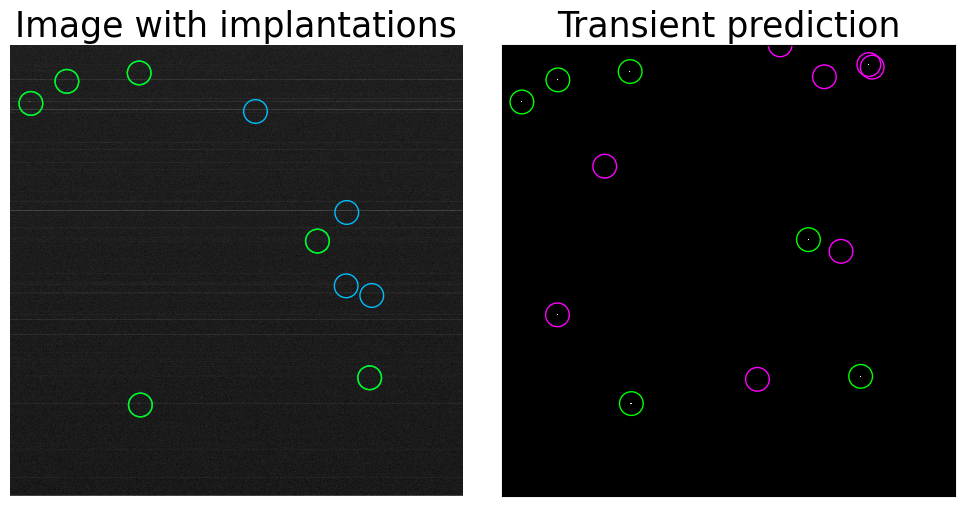

In [189]:
show_preds_tf("ztf_20221014279051_000501_zr_c16_x_0025.", df_checked_detections)

In [12]:
# below here they take the dataframes
df_correct_detections = pd.read_csv("/home/3155/thr99/df_correct_detections")
df_checked_detections = pd.read_csv("/home/3155/thr99/df_checked_detections")
df_missing_detections = pd.read_csv("/home/3155/thr99/df_missing_detections")
all_implant_intensities = np.hstack(
    (
        df_correct_detections["intensity_from_implant"].values,
        df_missing_detections["intensity"].values,
    )
)
df_false_detections = df_checked_detections[
    df_checked_detections["correctness"] == False
]

FileNotFoundError: [Errno 2] No such file or directory: '/home/3155/thr99/df_correct_detections'

In [12]:
def get_efficiencies(all_implant_intensities, correct_detections):
    """
    Let's make them both arrays
    i guess the output can be an array: size, efficiency, and poisson error
    """
    arr = []
    for num in np.unique(all_implant_intensities):
        total = np.sum(all_implant_intensities == num)
        found = np.sum(correct_detections == num)
        efficiency = found / total
        error = np.sqrt(total) / total
        arr.append([num, efficiency, error])
    arr = np.array(arr)
    return arr

In [15]:
effencies_arr = get_efficiencies(
    all_implant_intensities, df_correct_detections["intensity_from_implant"].values
)

In [16]:
def zoominthere2(loc, image, pimg, offset):
    """
    sometimes i see a transient location come up and i'm like
    what is that. can we zoom in there
    loc: (row, column) from nn prediction (not lined up with image)
    image: array (streak image)
    pimg: array (probability image)
    offset: difference between rows/cols of original and pimg (usually it is wid (10))
    returns: nothing but shows plot of zoomed in
    """
    wid = offset
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    row, col = loc
    print(loc)
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_ylim(col + wid - 20, col + wid + 20)
    ax[0].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[0].set_title("Image")
    # plt.colorbar()
    ax[1].imshow(pimg)
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Transient prediction")
    ax[2].plot(
        (
            image[:, int(col + wid)]
            + image[:, int(col + wid) + 1]
            + image[:, int(col + wid) - 1]
        )
        / 3
    )
    ax[2].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[2].set_title(
        "Time series average of image row " + str(int(col + wid)) + " and adjacent"
    )
    plt.tight_layout()
    # plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, wspace=0.1)
    plt.show()
    fig2, ax2 = plt.subplots(1, 1, figsize=(15, 2))
    ax2.plot(
        (
            image[:, int(col + wid)]
            + image[:, int(col + wid) + 1]
            + image[:, int(col + wid) - 1]
        )
        / 3
    )
    ax2.set_title("Entire streak time series")
    plt.show()
    fig3, ax3 = plt.subplots(1, 1, figsize=(15, 2))
    ax3.imshow(np.sqrt(image.T), aspect=20)
    ax3.set_ylim(col + wid - 5, col + wid + 5)
    ax3.set_title("Entire streak")
    plt.tight_layout()
    plt.show()
    # fig.suptitle("zoom in on pimg")

In [17]:
def zoominthere_pretty(loc, image, pimg, offset):
    """
    sometimes i see a transient location come up and i'm like
    what is that. can we zoom in there
    loc: (row, column) from nn prediction (not lined up with image)
    image: array (streak image)
    pimg: array (probability image)
    offset: difference between rows/cols of original and pimg (usually it is wid (10))
    returns: nothing but shows plot of zoomed in
    """
    wid = offset
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    row, col = loc
    print(loc)
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_ylim(col + wid - 20, col + wid + 20)
    ax[0].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[0].set_title("Image", fontsize=25)  # , fontweight='bold')
    # plt.colorbar()
    ax[1].imshow(pimg)
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Transient prediction", fontsize=25)
    ax[2].plot(
        (
            image[:, int(col + wid)]
            + image[:, int(col + wid) + 1]
            + image[:, int(col + wid) - 1]
        )
        / 3
    )
    ax[2].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[2].set_title("Streak time series", fontsize=25)
    ax[0].set_axis_off()
    ax[1].set_axis_off()
    ax[2].set_xticks([])
    ax[2].set_yticks([])
    ax[2].set_xticklabels([])
    ax[2].set_yticklabels([])
    plt.tight_layout()
    # plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, wspace=0.1)
    plt.show()
    # fig2, ax2 = plt.subplots(1, 1, figsize=(15, 2))
    # ax2.plot((image[:,int(col+wid)]+image[:,int(col+wid)+1]+image[:,int(col+wid)-1])/3)
    # ax2.set_title("Entire streak time series")
    # plt.show()
    # fig3, ax3 = plt.subplots(1, 1, figsize=(15, 2))
    # ax3.imshow(np.sqrt(image.T), aspect=20)
    # ax3.set_ylim(col+wid-5,col+wid+5)
    # ax3.set_title("Entire streak")
    # plt.tight_layout()
    # plt.show()
    # fig.suptitle("zoom in on pimg")

In [18]:
def look_at_detection(df, row, pretty=False):
    our_guy = df.iloc[row]
    image_row = our_guy["row_from_nn"]
    col = our_guy["col_from_nn"]
    image = np.load(
        "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/images/"
        + our_guy["filename"]
        + "_implanted10.npy"
    )
    predsarray = np.load(
        "/lustre/lrspec/ZTF_data/2022_1014_copy/full_transient_extractions/"
        + our_guy["filename"]
        + "_extraction_predsarray.npy"
    )
    predsarray = predsarray.reshape(3052, 3060, 3)
    print(our_guy["filename"])
    if pretty == False:
        zoominthere2((image_row, col), image, predsarray[:, :, 1] > 0.99, 10)
    else:
        zoominthere_pretty((image_row, col), image, predsarray[:, :, 1] > 0.99, 10)
    plt.show()

ztf_20221014162894_000802_zg_c12_x_0015.
(1100.404255319149, 797.3617021276596)


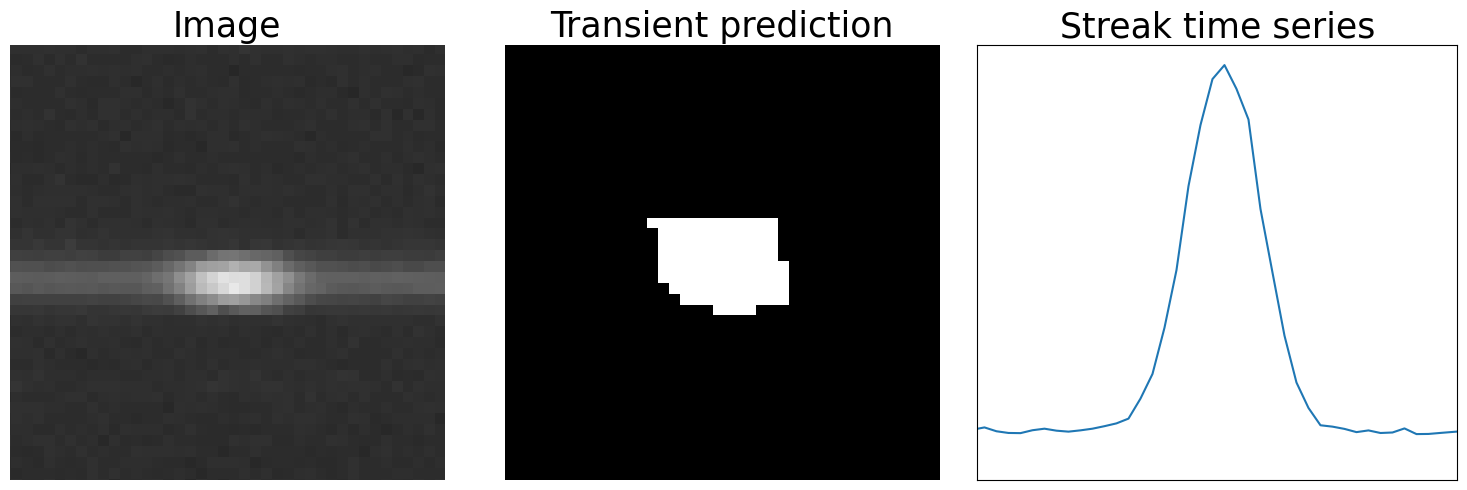

ztf_20221014162894_000802_zg_c12_x_0015.
(2686.550561797753, 662.5955056179776)


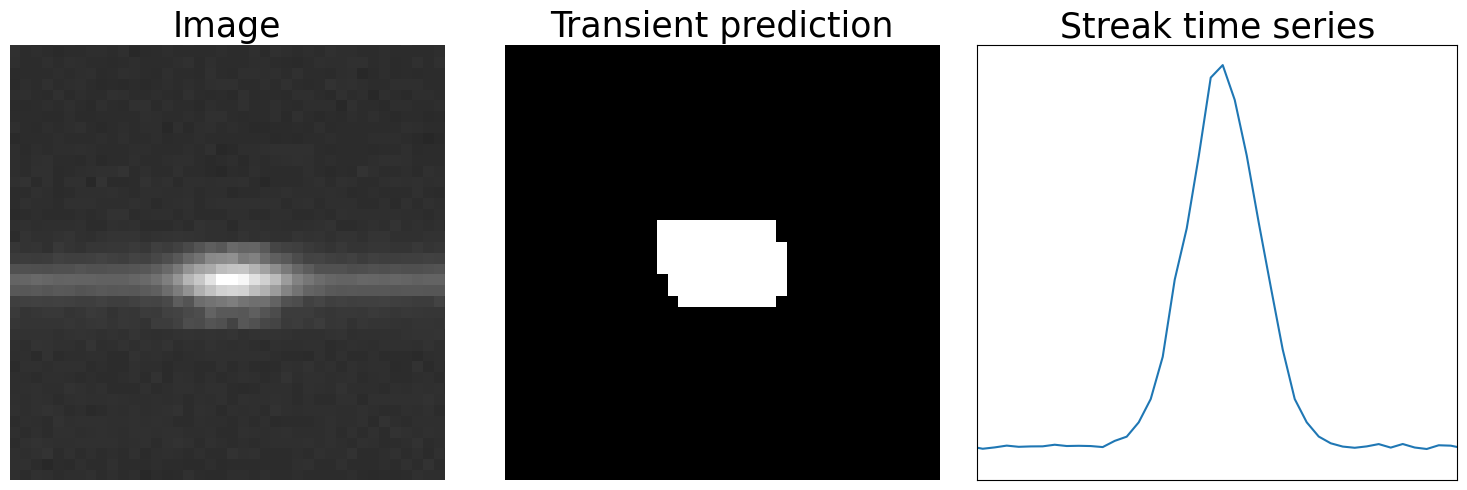

ztf_20221014162894_000802_zg_c12_x_0015.
(2774.8545454545456, 835.9454545454546)


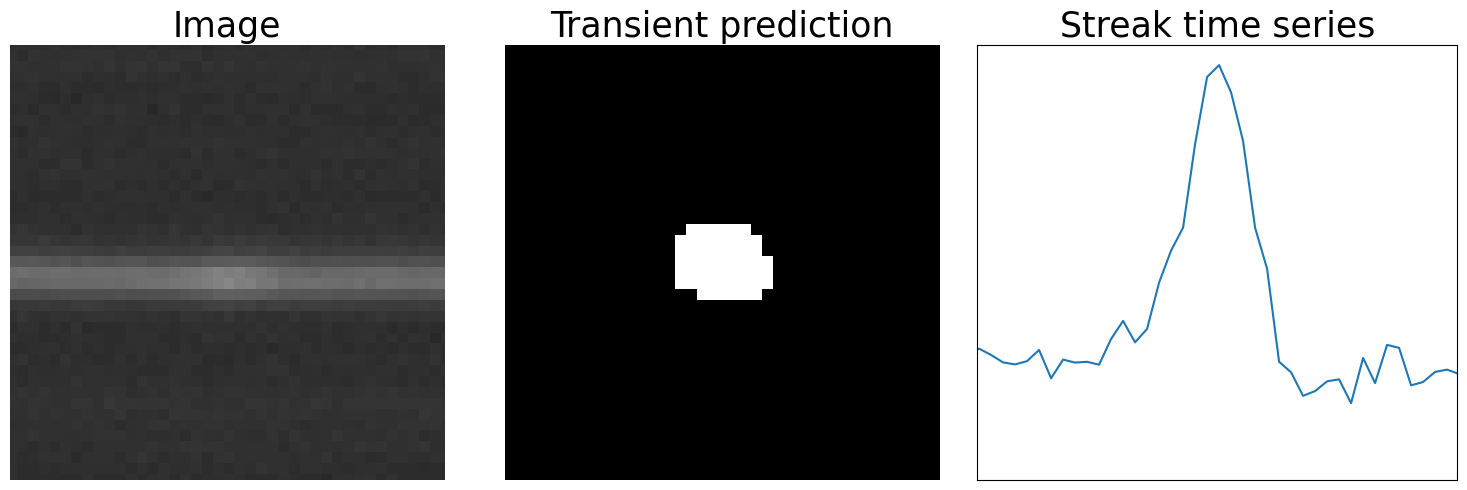

ztf_20221014162894_000802_zg_c12_x_0015.
(2798.803571428572, 1386.8392857142858)


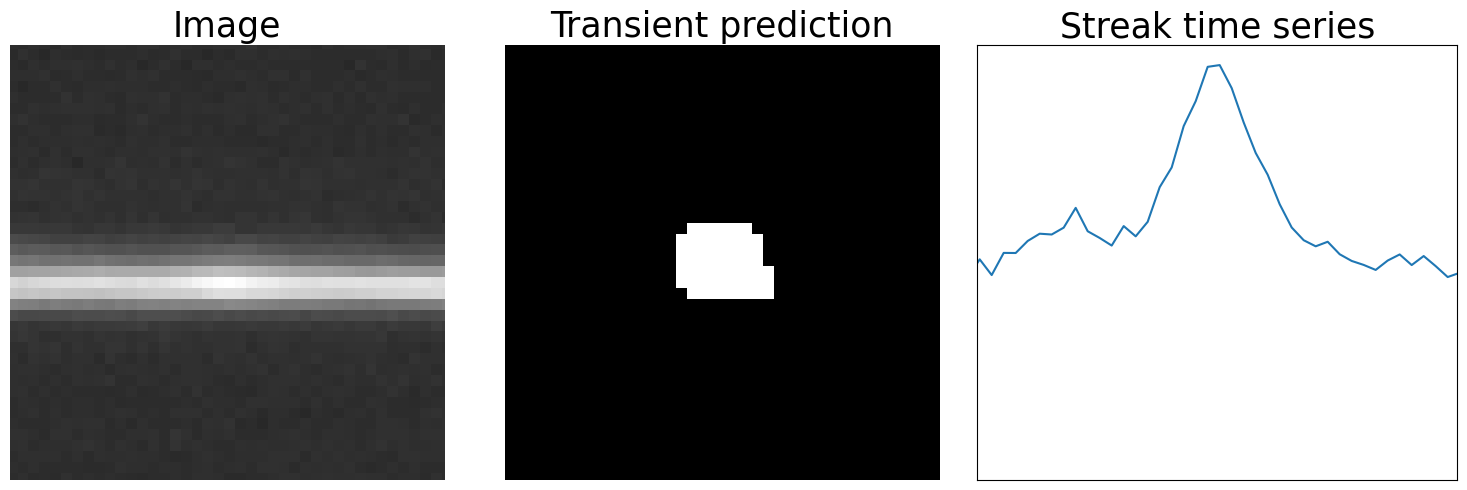

ztf_20221014169178_000802_zi_c11_x_0027.
(1079.914893617021, 1242.468085106383)


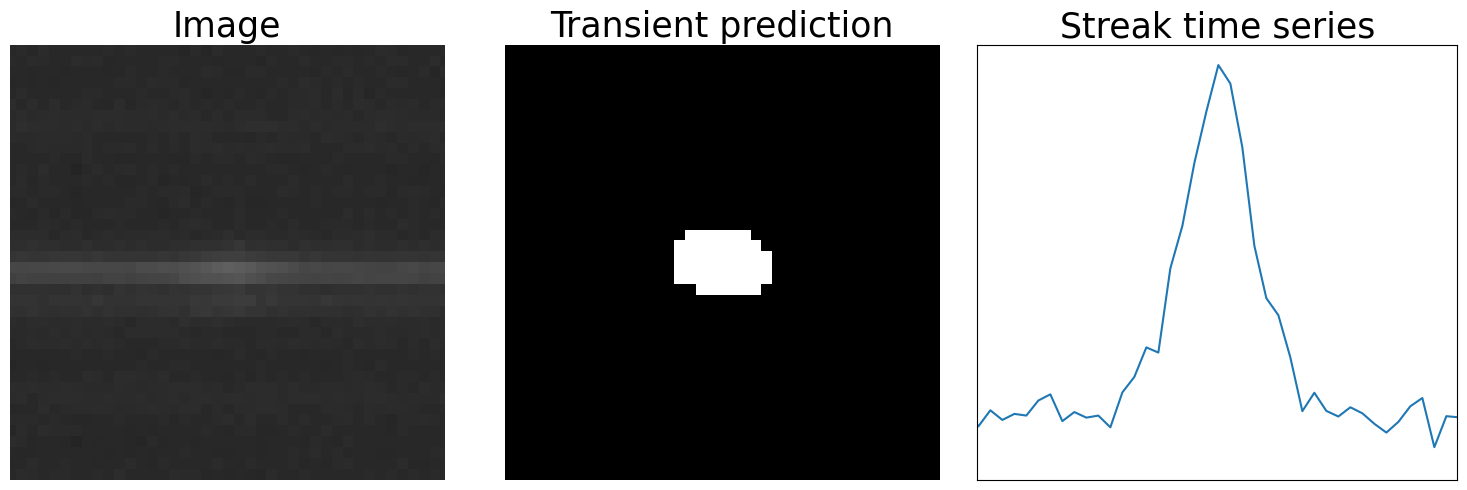

In [19]:
for i in range(5):
    look_at_detection(df_correct_detections, i, True)

ztf_20221014169178_000802_zi_c01_x_0029.
(2258.0, 1017.625)


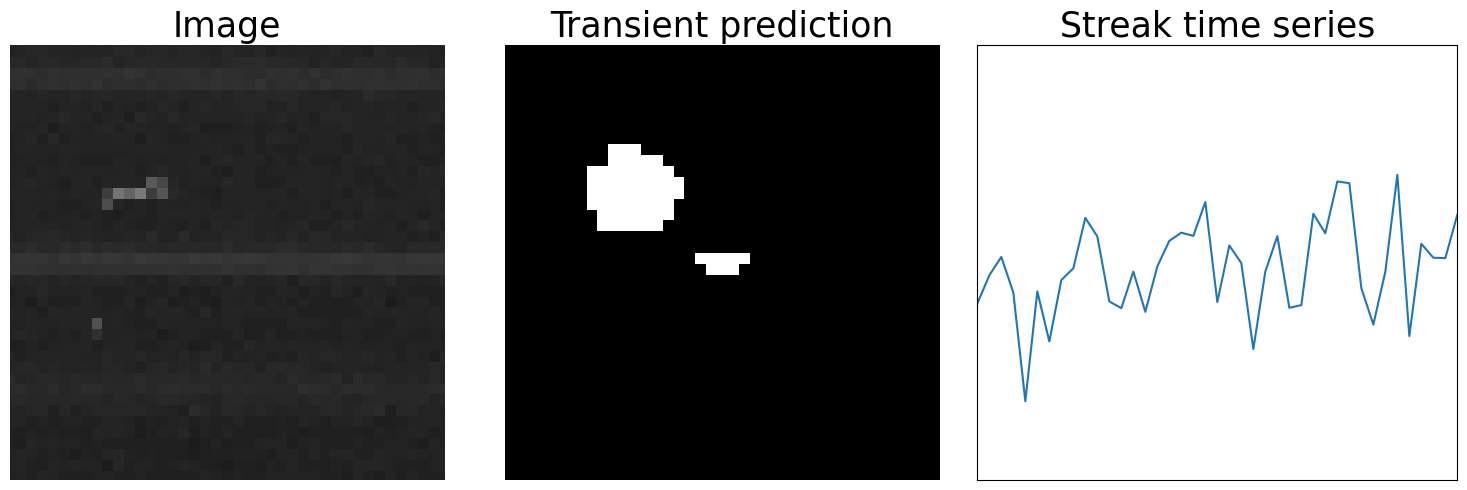

ztf_20221014279051_000501_zr_c16_x_0017.
(466.0, 1685.0)


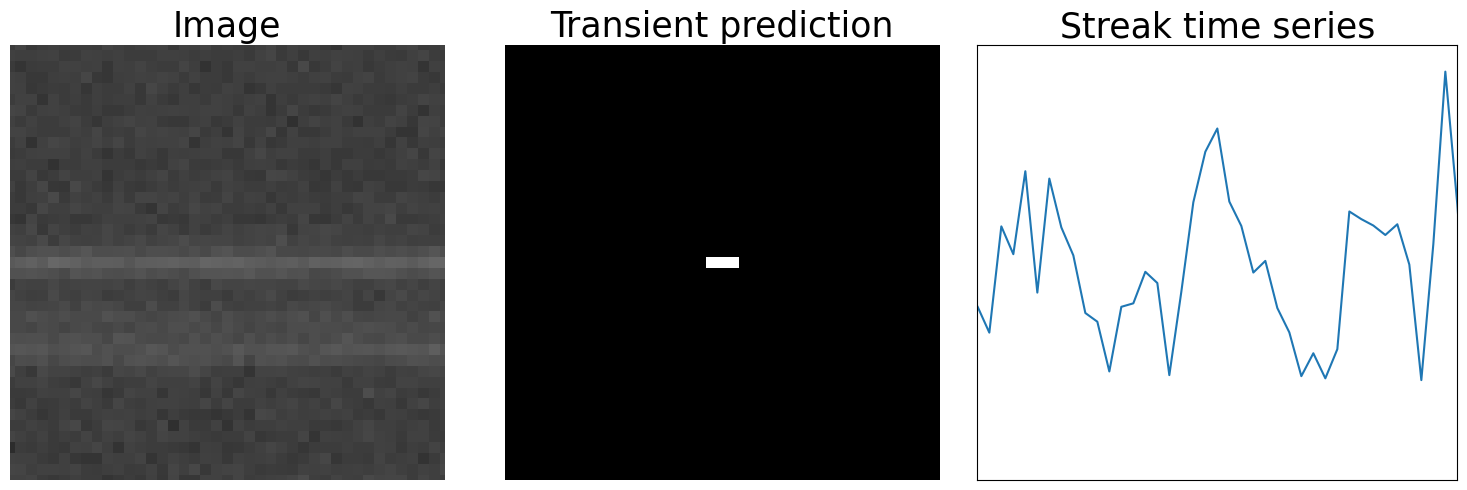

ztf_20221014279051_000501_zr_c16_x_0017.
(1293.0, 761.5)


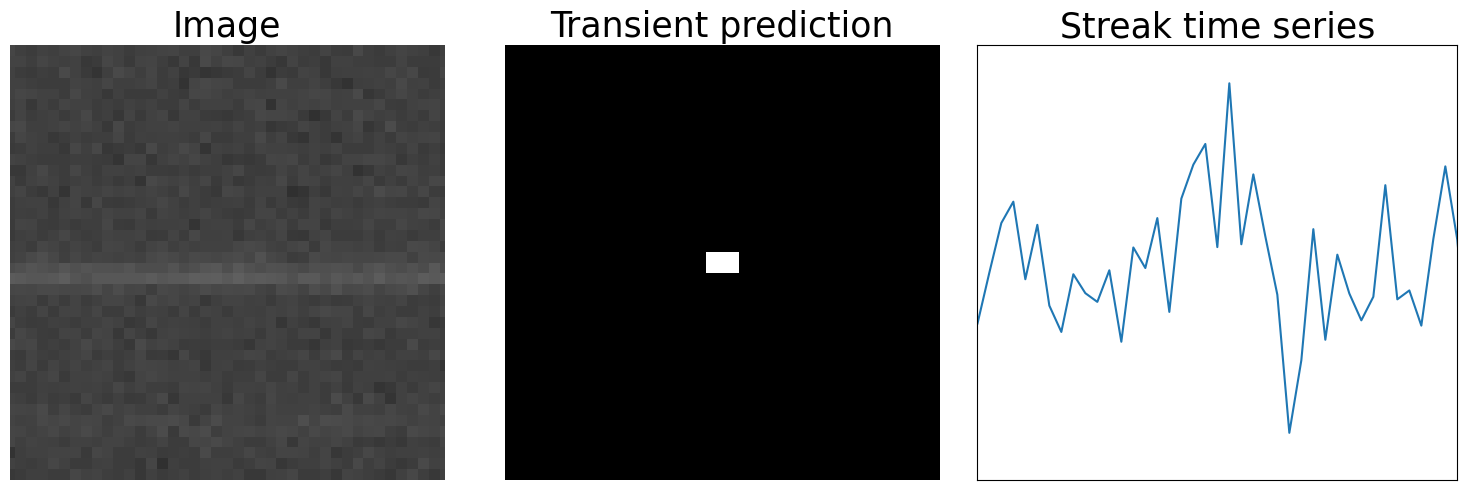

In [22]:
for i in range(3):
    look_at_detection(
        df_false_detections[df_false_detections["cosmic_ray_flag"] == 1], i, True
    )

In [23]:
df_extras = df_false_detections[
    df_false_detections["filename"] == "ztf_20221014279051_000501_zr_c16_x_0025."
]

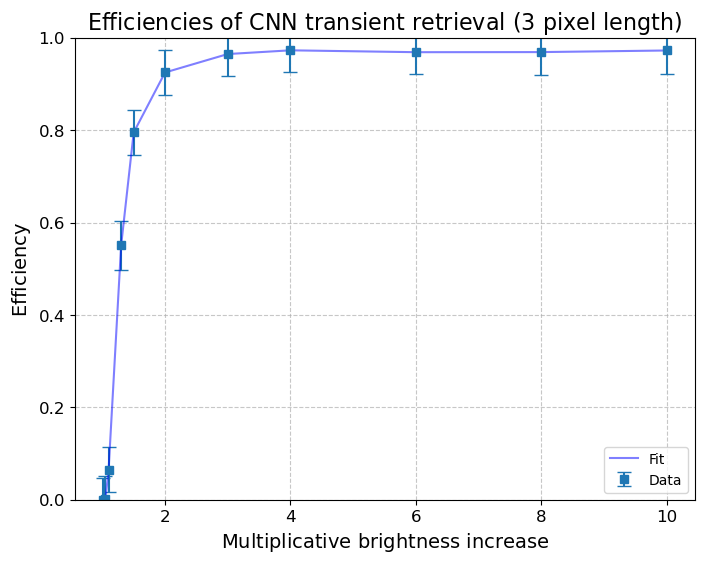

In [24]:
# Assuming effencies_arr is your data array

# Increase figure size
plt.figure(figsize=(8, 6))

# Plotting with error bars
plt.errorbar(
    effencies_arr[:, 0],
    effencies_arr[:, 1],
    yerr=effencies_arr[:, 2],
    fmt="s",
    label="Data",
    capsize=5,
)

# Adding a line for better visibility
plt.plot(
    effencies_arr[:, 0],
    effencies_arr[:, 1],
    linestyle="-",
    color="blue",
    alpha=0.5,
    label="Fit",
)

# Set title using LaTeX for better formatting
plt.title(
    r"$\mathrm{Efficiencies\ of\ CNN\ transient\ retrieval\ (3\ pixel\ length)}$",
    fontsize=16,
)  # \ thr = 0.99}

# Labeling axes using LaTeX
plt.xlabel(r"$\mathrm{Multiplicative\ brightness\ increase}$", fontsize=14)
plt.ylabel(r"$\mathrm{Efficiency}$", fontsize=14)

# Set axis limits
plt.ylim(0, 1)

# Add a grid
plt.grid(True, linestyle="--", alpha=0.7)

# Increase font size for tick labels
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add legend
plt.legend()

# Display the plot
plt.show()

In [25]:
def plot_time_series(row, col, image):
    """ """
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"

    column = int(col)
    gs_kw = dict(width_ratios=[3, 1], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper right"], ["lower left", "lower right"]],
        gridspec_kw=gs_kw,
        figsize=(5.5, 3.5),
        layout="constrained",
    )
    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images
    axd["lower left"].scatter(
        np.arange(len(image[:, column])),
        image[:, column],
        s=np.full(len(image[:, column]), 6),
        color="black",
        marker="|",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["upper left"].imshow(np.sqrt(image).T, aspect=80, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 4, column + 4)
    axd["upper right"].imshow(np.sqrt(image).T, aspect=1.4, cmap="gist_gray")
    axd["upper right"].set_xlim(row - 9, row + 9)
    axd["upper right"].set_ylim(column - 4, column + 4)
    # scatter(np.arange(len(image[:,column])-2*wid)+wid, image[wid:-wid,column],
    axd["lower right"].scatter(
        np.arange(len(image[:, column])),
        image[:, column],
        s=np.full(len(image[:, column]), 10),
        color="black",
        marker="|",
    )
    axd["lower right"].set_xlim(row - 9, row + 9)
    axd["upper right"].set_axis_off()
    # axd['upper left'].set_axis_off()
    # axd['lower right'].set_xticks([])
    axd["lower right"].set_yticks([])
    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_yticks([])
    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )
    axd["lower right"].set_xticks(np.linspace(row - 9, row + 9, 3))
    axd["lower right"].set_xticklabels([0.87, 0.88, 0.89])

    # axd['lower left'].set_yticklabels([])
    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Flux (normalized)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)
    axd["lower right"].set_xlabel("Time (seconds)", fontsize=12)
    # fig.suptitle('column '+str(column)+" (b=transient, g=streak, r=background)")
    # plt.savefig("/home/3155/timeseries_outputs/column "+str(column))
    # if type(pathtosave)==str:
    #     plt.savefig(pathtosave+"column "+str(column))
    # plt.tight_layout()
    fig.suptitle("Streak with implanted transient", fontsize=14)
    plt.show()
    plt.close()

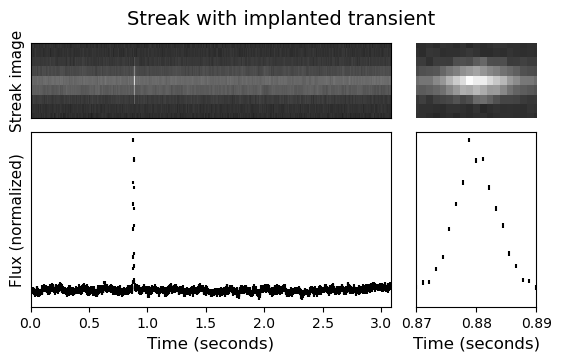

In [26]:
plot_time_series(881, 2435, testimp)

In [38]:
def get_file_info(filename_start, toprint=False):
    directory = "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/info/"
    image_filename_full = directory + filename_start + "_implanted10_info.npy"
    file_info = np.load(image_filename_full, allow_pickle=True)
    if toprint == True:
        print(file_info)
    return file_info

In [39]:
get_file_info("ztf_20221014279051_000501_zr_c16_x_0025.")

array([[1.910e+02, 8.730e+02, 6.000e+00, 3.000e+00],
       [2.480e+02, 3.840e+02, 1.500e+00, 3.000e+00],
       [3.970e+02, 1.410e+02, 1.000e+01, 3.000e+00],
       [4.520e+02, 1.659e+03, 1.010e+00, 3.000e+00],
       [1.135e+03, 2.276e+03, 1.050e+00, 3.000e+00],
       [1.328e+03, 2.078e+03, 2.000e+00, 3.000e+00],
       [1.631e+03, 2.272e+03, 1.050e+00, 3.000e+00],
       [1.696e+03, 2.445e+03, 1.100e+00, 3.000e+00],
       [2.252e+03, 2.431e+03, 8.000e+00, 3.000e+00],
       [2.436e+03, 8.810e+02, 6.000e+00, 3.000e+00]])

In [86]:
def plot_time_series_zoom_notrans(df, index, col, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    # col = int(df.iloc[index]["col_from_nn"])+10

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[1].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = ff.get_image_background(image)

    # subtracting background
    imagenobackground = image - np.full(np.shape(image), background)
    averages = np.average(imagenobackground, axis=0)
    mid = int(col)
    indices_to_check = [
        mid - 10,
        mid - 11,
        mid - 12,
        mid - 13,
        mid - 14,
        mid - 15,
        mid - 16,
        mid - 17,
        mid - 18,
        mid - 19,
        mid - 20,
        mid - 9,
        mid - 8,
        mid - 7,
        mid - 6,
        mid - 5,
        mid - 4,
        mid - 3,
        mid - 2,
        mid - 1,
        mid,
        mid + 1,
        mid + 2,
        mid + 3,
        mid + 4,
        mid + 5,
        mid + 6,
        mid + 7,
        mid + 8,
        mid + 9,
        mid + 10,
        mid + 11,
        mid + 12,
        mid + 13,
        mid + 14,
        mid + 15,
        mid + 16,
        mid + 17,
        mid + 18,
        mid + 19,
        mid + 20,
    ]
    column_indices = []
    for ind in indices_to_check:
        if averages[ind] > 0.01:
            column_indices.append(ind)

    streaks = np.zeros((len(column_indices), len(image[:, column])))
    for i, inde in enumerate(column_indices):
        streaks[i] = imagenobackground[:, inde]
        # streaks[i] = image[:,inde]
    streakavg = np.average(streaks, axis=0)
    tot = np.sum(streaks, axis=0)
    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    axd["lower left"].set_ylim(0, 1499)
    axd["lower mid"].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Summed streak flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(image).T, aspect=1.05, cmap="gist_gray")
    axd["upper mid"].set_xlim(row - 80, row + 80)
    axd["upper mid"].set_ylim(column - 20, column + 20)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(row - 80, row + 80)
    axd["lower mid"].set_xticks(np.linspace(row - 80, row + 80, 3))
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()

    fig.suptitle("Star Streak and Corresponding Time Series", fontsize=24)

    plt.show()
    plt.close()

In [87]:
df_1014 = ff.getdf("1014")

/lustre/lrspec/ZTF_data/science_extractions/1014/df_detections_1014


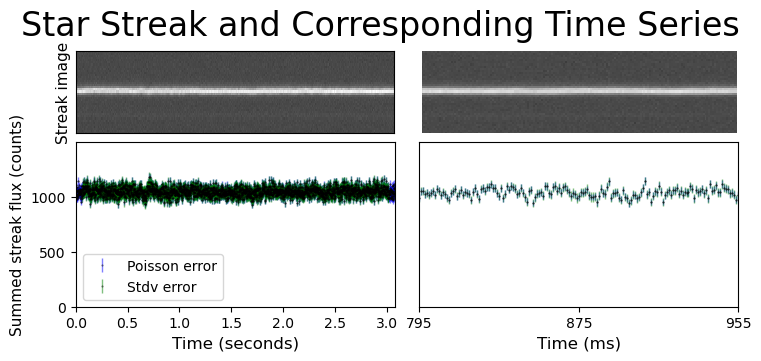

In [88]:
plot_time_series_zoom_notrans(df_1014, 5, 1142, "1014")

In [51]:
def gaussian_event(ys, M, sig, A, original_values):
    """ys should be the array of y values
    #m is the center y value
    #sig is the standard deviation
    #original_values is the original brightness (for each y value)
    #A is the maximum brightening. A-1 is in the code bc of that additional 1 later
    #return original_values * ((A-1) * (np.exp(-np.power(ys - M, 2.) / (2 * np.power(sig, 2.)))) + 1)
    """
    return original_values * (
        (A - 1) * (np.exp(-np.power(ys - M, 2.0) / (2 * np.power(sig, 2.0)))) + 1
    )

In [89]:
def plot_time_series_zoom_implant(df, index, col, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    # col = int(df.iloc[index]["col_from_nn"])+10

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[1].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = ff.get_image_background(image)

    # subtracting background
    imagenobackground = image - np.full(np.shape(image), background)
    averages = np.average(imagenobackground, axis=0)
    mid = int(col)
    indices_to_check = [
        mid - 10,
        mid - 11,
        mid - 12,
        mid - 13,
        mid - 14,
        mid - 15,
        mid - 16,
        mid - 17,
        mid - 18,
        mid - 19,
        mid - 20,
        mid - 9,
        mid - 8,
        mid - 7,
        mid - 6,
        mid - 5,
        mid - 4,
        mid - 3,
        mid - 2,
        mid - 1,
        mid,
        mid + 1,
        mid + 2,
        mid + 3,
        mid + 4,
        mid + 5,
        mid + 6,
        mid + 7,
        mid + 8,
        mid + 9,
        mid + 10,
        mid + 11,
        mid + 12,
        mid + 13,
        mid + 14,
        mid + 15,
        mid + 16,
        mid + 17,
        mid + 18,
        mid + 19,
        mid + 20,
    ]
    column_indices = []
    for ind in indices_to_check:
        if averages[ind] > 0.01:
            column_indices.append(ind)

    gaussianed_image = (
        imagenobackground.copy()
    )  # stamp array to modify with the gaussian brightening

    center_value_y = col
    sigma = 3
    intensity = 2
    for i in column_indices:
        gaussianed = gaussian_event(
            ys=np.linspace(
                0, imagenobackground.shape[0] - 1, imagenobackground.shape[0]
            ),
            M=center_value_y,
            sig=sigma,
            A=intensity,
            original_values=imagenobackground[:, i],
        )
        gaussianed_image[:, i] = gaussianed

    # adding back background
    gaussianed_image = gaussianed_image + np.full(np.shape(image), background)

    streaks = np.zeros((len(column_indices), len(image[:, column])))
    for i, inde in enumerate(column_indices):
        streaks[i] = gaussianed_image[:, inde]
        # streaks[i] = image[:,inde]
    streakavg = np.average(streaks, axis=0)
    tot = np.sum(streaks, axis=0)
    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    # axd['lower left'].set_ylim(0, 1499)
    # axd['lower mid'].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(gaussianed_image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Summed streak flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(gaussianed_image).T, aspect=1.05, cmap="gist_gray")
    axd["upper mid"].set_xlim(col - 80, col + 80)
    axd["upper mid"].set_ylim(column - 20, column + 20)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(col - 80, col + 80)
    axd["lower mid"].set_xticks(np.linspace(col - 80, col + 80, 3))
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()

    fig.suptitle("Implanted Transient in Star Streak/Time Series", fontsize=24)

    plt.show()
    plt.close()

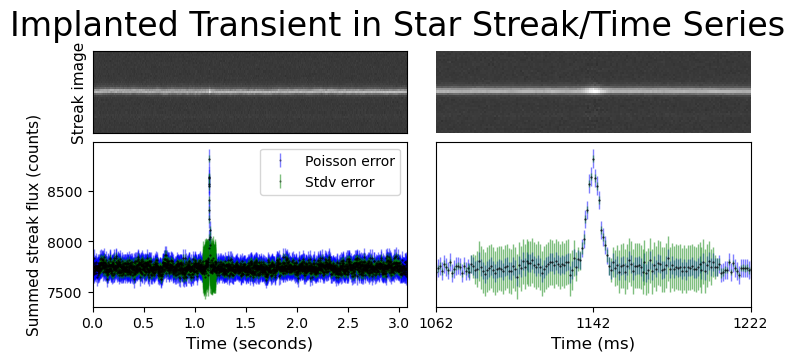

In [90]:
plot_time_series_zoom_implant(df_1014, 5, 1142, "1014")

In [124]:
def plot_time_series_zoom_transit(df, index, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[1].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = ff.get_image_background(image)

    # subtracting background
    imagenobackground = image - np.full(np.shape(image), background)
    averages = np.average(imagenobackground, axis=0)
    mid = int(col)
    indices_to_check = [
        mid - 9,
        mid - 8,
        mid - 7,
        mid - 6,
        mid - 5,
        mid - 4,
        mid - 3,
        mid - 2,
        mid - 1,
        mid,
        mid + 1,
        mid + 2,
        mid + 3,
        mid + 4,
        mid + 5,
        mid + 6,
        mid + 7,
        mid + 8,
        mid + 9,
    ]
    # mid-10, mid-11, mid-12, mid-13, mid-14,
    #                     mid-15, mid-16, mid-17, mid-18, mid-19, mid-20,
    column_indices = []
    for ind in indices_to_check:
        if averages[ind] > 0.01:
            column_indices.append(ind)

    streaks = np.zeros((len(column_indices), len(image[:, column])))
    for i, inde in enumerate(column_indices):
        streaks[i] = imagenobackground[:, inde]
        # streaks[i] = image[:,inde]
    streakavg = np.average(streaks, axis=0)
    tot = np.sum(streaks, axis=0)
    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    # axd['lower left'].set_ylim(0, 1499)
    # axd['lower mid'].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Summed streak flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(image).T, aspect=1.05, cmap="gist_gray")
    axd["upper mid"].set_xlim(row - 80, row + 80)
    axd["upper mid"].set_ylim(column - 20, column + 20)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(row - 80, row + 80)
    axd["lower mid"].set_xticks(np.linspace(row - 80, row + 80, 3))
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()

    fig.suptitle("Satellite Transit", fontsize=24)

    plt.show()
    plt.close()

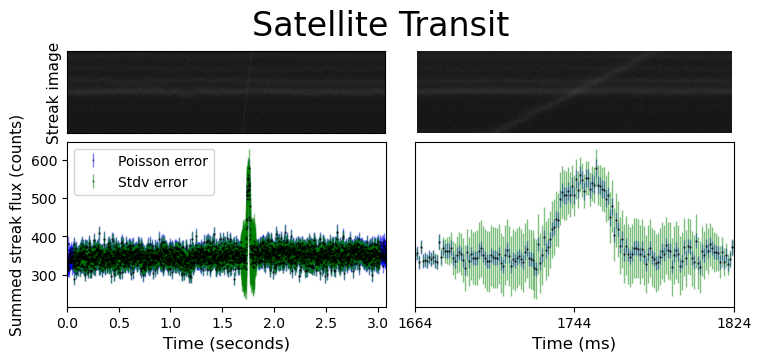

In [108]:
plot_time_series_zoom_transit(index=23297, direcname="1014", df=df_1014)
# index=23297, direcname="1014", df=df_1014
# index=4088, direcname="1014", df=df_1014
# index=4100, direcname="1014", df=df_1014

/tmp/ipykernel_27356/538845315.py:76: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt(tot)


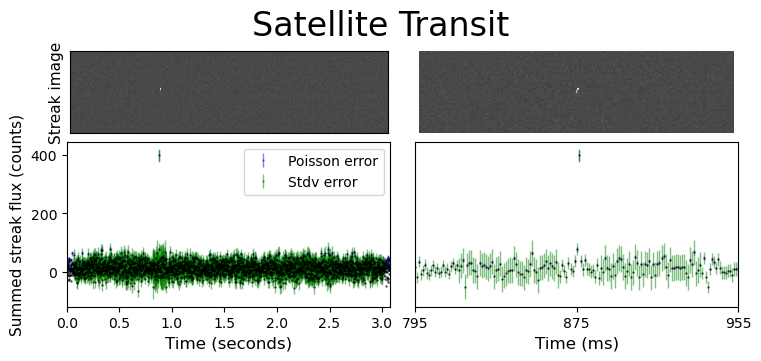

In [121]:
def plot_time_series_zoom_cr(df, index, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[1].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = ff.get_image_background(image)

    # subtracting background
    imagenobackground = image - np.full(np.shape(image), background)
    averages = np.average(imagenobackground, axis=0)
    mid = int(col)
    indices_to_check = [
        mid - 9,
        mid - 8,
        mid - 7,
        mid - 6,
        mid - 5,
        mid - 4,
        mid - 3,
        mid - 2,
        mid - 1,
        mid,
        mid + 1,
        mid + 2,
        mid + 3,
        mid + 4,
        mid + 5,
        mid + 6,
        mid + 7,
        mid + 8,
        mid + 9,
    ]
    # mid-10, mid-11, mid-12, mid-13, mid-14,
    #                     mid-15, mid-16, mid-17, mid-18, mid-19, mid-20,
    column_indices = []
    for ind in indices_to_check:
        if averages[ind] > 0.01:
            column_indices.append(ind)

    streaks = np.zeros((len(column_indices), len(image[:, column])))
    for i, inde in enumerate(column_indices):
        streaks[i] = imagenobackground[:, inde]
        # streaks[i] = image[:,inde]
    streakavg = np.average(streaks, axis=0)
    tot = np.sum(streaks, axis=0)
    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].plot(
        np.arange(len(streakavg))[row - 9 : row + 9],
        tot[row - 9 : row + 9],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=10,
    )

    axd["lower mid"].plot(
        np.arange(len(streakavg))[row - 9 : row + 9],
        tot[row - 9 : row + 9],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=10,
    )

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    # axd['lower left'].set_ylim(0, 1499)
    # axd['lower mid'].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Summed streak flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(image).T, aspect=0.3, cmap="gist_gray")
    axd["upper mid"].set_xlim(row - 20, row + 20)
    axd["upper mid"].set_ylim(column - 20, column + 20)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(row - 20, row + 20)
    axd["lower mid"].set_xticks(np.linspace(row - 20, row + 20, 3))
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()

    fig.suptitle("Cosmic Ray", fontsize=24)

    plt.show()
    plt.close()

/tmp/ipykernel_27356/4109214575.py:76: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt(tot)


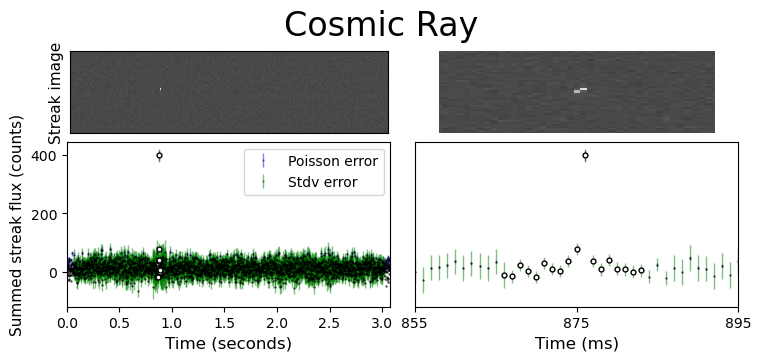

In [122]:
plot_time_series_zoom_cr(index=5, direcname="1014", df=df_1014)

In [127]:
df_1019 = ff.getdf("1019")

/lustre/lrspec/ZTF_data/science_extractions/1019/df_detections_1019


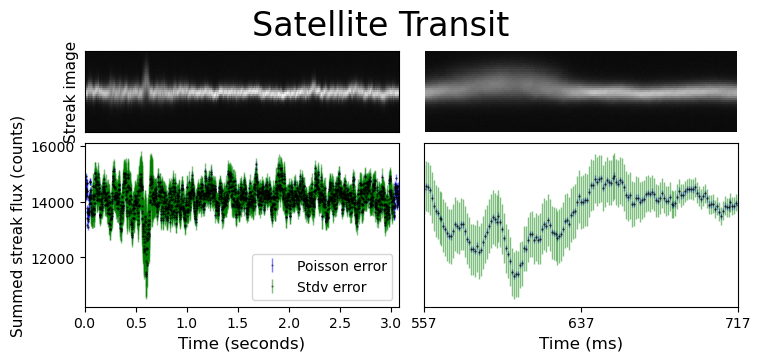

In [151]:
def plot_time_series_zoom_occult(df, index, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[1].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = ff.get_image_background(image)

    # subtracting background
    imagenobackground = image - np.full(np.shape(image), background)
    averages = np.average(imagenobackground, axis=0)
    mid = int(col)
    indices_to_check = [
        mid - 6,
        mid - 5,
        mid - 4,
        mid - 3,
        mid - 2,
        mid - 1,
        mid,
        mid + 1,
        mid + 2,
        mid + 3,
        mid + 4,
        mid + 5,
    ]
    # mid-10, mid-11, mid-12, mid-13, mid-14,
    #                     mid-15, mid-16, mid-17, mid-18, mid-19, mid-20,
    column_indices = []
    for ind in indices_to_check:
        if averages[ind] > 0.01:
            column_indices.append(ind)

    streaks = np.zeros((len(column_indices), len(image[:, column])))
    for i, inde in enumerate(column_indices):
        streaks[i] = imagenobackground[:, inde]
        # streaks[i] = image[:,inde]
    streakavg = np.average(streaks, axis=0)
    tot = np.sum(streaks, axis=0)
    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    # axd['lower left'].set_ylim(0, 1499)
    # axd['lower mid'].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Summed streak flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(image).T, aspect=3, cmap="gist_gray")
    axd["upper mid"].set_xlim(row - 250, row + 200)
    axd["upper mid"].set_ylim(column - 20, column + 20)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(row - 250, row + 200)
    axd["lower mid"].set_xticks(np.linspace(row - 250, row + 200, 3))
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()

    fig.suptitle("Occultation?", fontsize=24)

    axd["lower mid"].plot(
        np.arange(len(streakavg))[row - 90 : row + 10],
        tot[row - 90 : row + 10],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=20,
    )

    axd["lower left"].plot(
        np.arange(len(streakavg))[row - 90 : row + 10],
        tot[row - 90 : row + 10],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=20,
    )

    plt.show()
    plt.close()

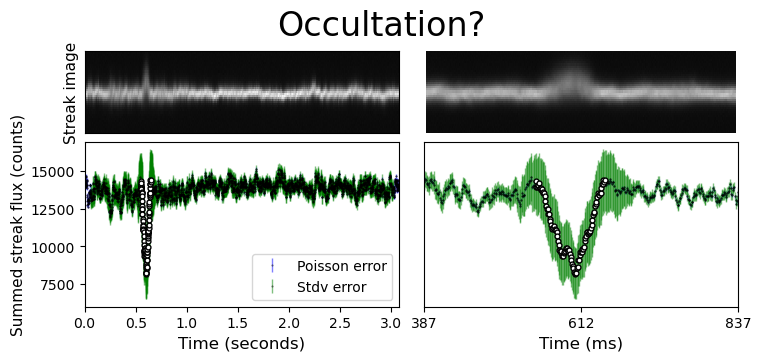

In [152]:
plot_time_series_zoom_occult(df_1019, 133424, "1019")

In [147]:
def plot_time_series_zoom_occult_wide(df, index, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[1].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = ff.get_image_background(image)

    # subtracting background
    imagenobackground = image - np.full(np.shape(image), background)
    averages = np.average(imagenobackground, axis=0)
    mid = int(col)
    indices_to_check = [
        mid - 10,
        mid - 11,
        mid - 12,
        mid - 13,
        mid - 14,
        mid - 15,
        mid - 16,
        mid - 17,
        mid - 18,
        mid - 19,
        mid - 20,
        mid - 9,
        mid - 8,
        mid - 7,
        mid - 6,
        mid - 5,
        mid - 4,
        mid - 3,
        mid - 2,
        mid - 1,
        mid,
        mid + 1,
        mid + 2,
        mid + 3,
        mid + 4,
        mid + 5,
        mid + 6,
        mid + 7,
        mid + 8,
        mid + 9,
        mid + 10,
        mid + 11,
        mid + 12,
        mid + 13,
        mid + 14,
        mid + 15,
        mid + 16,
        mid + 17,
        mid + 18,
        mid + 19,
        mid + 20,
    ]
    column_indices = []
    for ind in indices_to_check:
        if averages[ind] > 0.01:
            column_indices.append(ind)

    streaks = np.zeros((len(column_indices), len(image[:, column])))
    for i, inde in enumerate(column_indices):
        streaks[i] = imagenobackground[:, inde]
        # streaks[i] = image[:,inde]
    streakavg = np.average(streaks, axis=0)
    tot = np.sum(streaks, axis=0)
    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    # axd['lower left'].set_ylim(0, 1499)
    # axd['lower mid'].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Summed streak flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(image).T, aspect=3, cmap="gist_gray")
    axd["upper mid"].set_xlim(row - 250, row + 200)
    axd["upper mid"].set_ylim(column - 20, column + 20)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(row - 250, row + 200)
    axd["lower mid"].set_xticks(np.linspace(row - 250, row + 200, 3))
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()

    axd["lower mid"].plot(
        np.arange(len(streakavg))[row - 90 : row + 10],
        tot[row - 90 : row + 10],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=20,
    )

    axd["lower left"].plot(
        np.arange(len(streakavg))[row - 90 : row + 10],
        tot[row - 90 : row + 10],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=20,
    )

    fig.suptitle("Occultation?", fontsize=24)

    plt.show()
    plt.close()

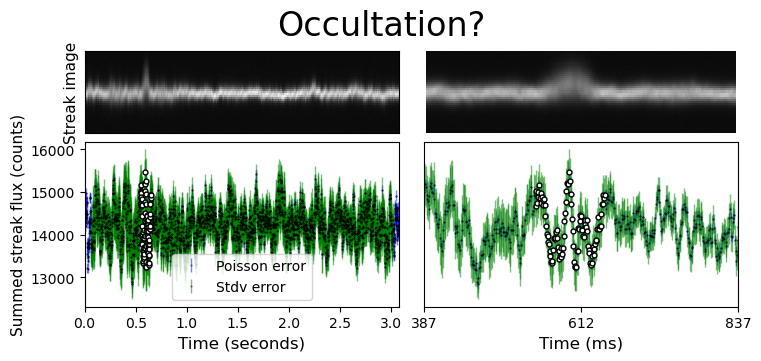

In [148]:
plot_time_series_zoom_occult_wide(df_1019, 133424, "1019")

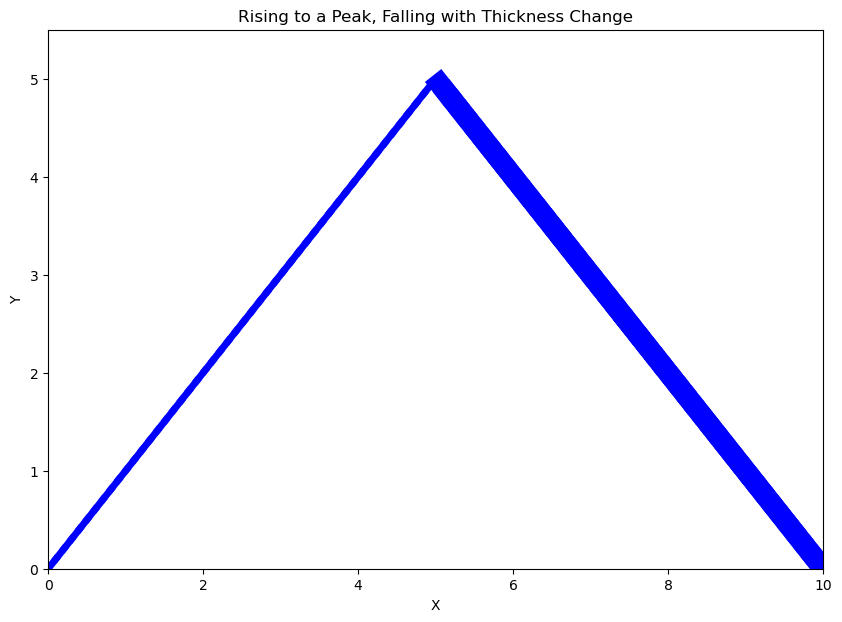

In [7]:
# Define data points
x = np.linspace(0, 10, 100)  # X-axis values
y = np.piecewise(
    x, [x <= 5, x > 5], [lambda x: x, lambda x: 10 - x]
)  # Linear rise and fall

# Define thickness (varying between rise and fall)
linewidths = np.piecewise(x, [x <= 5, x > 5], [8, 15])  # Thicker on the fall

# Create the plot
fig, ax = plt.subplots()

for i in range(len(x) - 1):
    ax.plot(x[i : i + 2], y[i : i + 2], color="blue", linewidth=linewidths[i])

# Set plot limits and labels
ax.set_xlim([0, 10])
ax.set_ylim([0, 5.5])
ax.set_xlabel("Magnitudes")
ax.set_ylabel("Y")
ax.set_title("Rising to a Peak, Falling with Thickness Change")

plt.show()